<a href="https://colab.research.google.com/github/mybenkhadda/GEMS---drivendata/blob/main/notebooks/colab/GEMS_DISCOVERY_GEOMOE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/mybenkhadda/GEMS---drivendata/blob/main/notebooks/colab/GEMS_DISCOVERY_GEOMOE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GEMS discovery-first GeoMoE (code rev dgm.1-r1)

**One experiment, one CONFIG, run top to bottom.** Candidate discovery -> geological experts -> static / rule / learned gating -> official DTI under three validation scenarios -> a validated GeoTIFF **only if** the predeclared selection rule selects a model.

| | |
|---|---|
| Runtime | Colab **CPU**, High-RAM recommended. No GPU, no neural network is trained. |
| Inputs (read-only) | the frozen B0 / B1 / W2 artifacts the submission factory attaches (`outputs/p6_fast_track/...`, experiments, folds, template), G01/G02 run, cached M7 DEM mosaic if present |
| Outputs | `MyDrive/GEMS_2/outputs/discovery_geomoe/` (audit, validation, candidates, experts, gating, predictions, submissions, figures, reports, manifests) |
| Code | `gems_bench/geomoe/` (`run.DiscoveryGeoMoE`), config `configs/geomoe/discovery_geomoe.yaml`, docs `docs/geomoe/DISCOVERY_GEOMOE.md` |

Scenarios: **V1** whole withheld systems (existing discovery splits), **V2** network completion (real mapped tips / branches / splays / sub-sections withheld inside each geo fold), **V3** geographic folds. Models: **A_pixel** frozen W2 (reference, public 0.0942), **A_seg** W2 on the unified pool, **B** static fusion, **C** rule gate (+ ablations), **D** learned gate (only if the coverage gate allows it).

**After a disconnect:** restart the session and run every cell again. Finished stages print `SKIP_CACHED`; finished candidate units print `reused`.

## 1 - Configuration (the only cell you edit)

`mode`: `FULL` | `DIAGNOSTIC` (everything except the GeoTIFF) | `RESUME` (= FULL, cache forced) | `REPORT_ONLY` (attach + audit + reports). `experts`: switch a family's layers off (`dem`: `cached_only` never downloads). `experiments.learned_gate`: `conditional` (stage 06 decides), `True` (forced, recorded), `False`. `export.exploratory`: also write a clearly labelled EXPLORATORY file when the rule retains W2.

In [1]:
CONFIG = {
    'repo': 'mybenkhadda/GEMS---drivendata',
    'ref': 'main',                          # pin the pushed commit SHA for a reproducible run
    'drive_root': '/content/drive/MyDrive/GEMS_2',
    'local_root': '/content/gems_work',

    'mode': 'FULL',                         # FULL | DIAGNOSTIC | RESUME | REPORT_ONLY
    'reuse_cached': True,
    'device': 'cpu',

    'experts': {
        'cnn': True,
        'w2': True,
        'magnetic_gravity': True,
        'g01_g02': True,
        'dem': 'cached_only',               # cached_only | off  (never a DEM download)
        'network': True,
    },
    'experiments': {
        'validation_audit': True,
        'candidate_ceiling': True,
        'static_fusion': True,
        'rule_gate': True,
        'learned_gate': 'conditional',      # conditional | True | False
        'deployment_comparison': True,
    },
    'export': {
        'enabled': True,
        'only_validated': True,
        'exploratory': False,               # True: also write an EXPLORATORY file when W2 is retained
        'manual_upload': True,              # must stay True
    },
    'save_png': True,
    'sync_to_drive': True,
    'overrides': {},                        # optional overrides of configs/geomoe/discovery_geomoe.yaml
}
PRIVATE_REPO = False
RUN_PYTEST = True                           # run tests/test_discovery_geomoe.py (synthetic) before any export
EXPECT = {'code_rev': 'dgm.1-r1', 'commit': None}   # set 'commit' to the pushed SHA

## 2 - Environment, Drive, frozen engine

Mounts Drive, clones the pinned ref, installs the package, builds the submission factory (the existing frozen-engine loader; it exports nothing here) and the GeoMoE runner. The runtime must be fresh (`gems_bench` not yet imported).

In [2]:
import base64, os, subprocess, sys
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')
CODE = '/content/GEMS'
REPO_URL = 'https://github.com/' + CONFIG['repo'] + '.git'

def _git_env():
    if not PRIVATE_REPO:
        return None
    from google.colab import userdata
    hdr = base64.b64encode(('x-access-token:' + (userdata.get('GITHUB_TOKEN') or '')).encode()).decode()
    return {**os.environ, 'GIT_CONFIG_COUNT': '1', 'GIT_CONFIG_KEY_0': 'http.https://github.com/.extraheader',
            'GIT_CONFIG_VALUE_0': 'AUTHORIZATION: basic ' + hdr}

def git(*args, auth=False, check=True):
    r = subprocess.run(['git', *args], capture_output=True, text=True, env=_git_env() if auth else None)
    if check and r.returncode:
        raise RuntimeError('git ' + ' '.join(args[:4]) + ' failed:\n' + r.stderr[-1500:])
    return r

if not Path(CODE, '.git').exists():
    git('clone', '-q', REPO_URL, CODE, auth=True)
git('-C', CODE, 'fetch', '-q', '--tags', 'origin', auth=True)
ref = CONFIG['ref']
if git('-C', CODE, 'rev-parse', '--verify', '-q', 'refs/remotes/origin/' + ref, check=False).returncode == 0:
    git('-C', CODE, 'checkout', '-q', '-B', 'geomoe_colab_active', 'origin/' + ref)
else:
    git('-C', CODE, 'checkout', '-q', '--detach', ref)
HEAD = git('-C', CODE, 'rev-parse', 'HEAD').stdout.strip()
if 'gems_bench' in sys.modules:
    raise RuntimeError('gems_bench already imported: Runtime -> Restart session, then run from the top')
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', CODE + '[colab]'], check=True)
sys.path.insert(0, CODE)
os.environ['GEMS_CODE_COMMIT'] = HEAD

import pandas as pd
from IPython.display import Image, Markdown, display
import gems_bench.geomoe as GM
from gems_bench.geomoe import run as GR, selftest as GST
from gems_bench.leaderboard_focus import factory as FA
assert GM.GEOMOE_CODE_REV == EXPECT['code_rev'], f'code rev {GM.GEOMOE_CODE_REV} != {EXPECT["code_rev"]}'
assert not EXPECT['commit'] or HEAD.startswith(EXPECT['commit']), f'HEAD {HEAD} != {EXPECT["commit"]}'
NB = GR.notebook_config(CONFIG)
F = FA.Factory(GR.factory_config(NB), HEAD)     # frozen-engine loader only (no factory candidate is exported)
G = GR.DiscoveryGeoMoE(CONFIG, HEAD, factory=F)
RUN_ALL = G.run                                   # optional one-call entry point == cells 4-16 below
OUT = G.ws.root

def show(rel, cols=None, n=40):
    p = OUT / rel
    if not p.exists():
        print('ABSENT:', rel); return None
    df = pd.read_csv(p) if p.suffix == '.csv' else pd.read_parquet(p)
    display(df[[c for c in (cols or df.columns) if c in df]].head(n)); return df

print('SHA', HEAD, '| code rev', GM.GEOMOE_CODE_REV, '| mode', NB['mode'])
print('Drive outputs:', G.drive / G.out)

Mounted at /content/drive
SHA 7dab78fa1232ad92ca9b2ac19dfbf2fa3aefaab5 | code rev dgm.1-r1 | mode FULL
Drive outputs: /content/drive/MyDrive/GEMS_2/outputs/discovery_geomoe


## 3 - Synthetic self-tests (before anything else)

GeoMoE contracts (V2 withholding uses real pixels only, leakage detection, FastScorer == official reference, known-fault masking, distance bands, dedup, provenance, oracle accounting, missing experts never zero, cross-fitted normalisation, gate weights + analytic gradient, collapse, PU targets, fair budgets, rule gate, falsifiable selection, coverage gate, read-back contract) + the pytest file. Stage 12 re-runs them and refuses to export on a critical failure.

In [3]:
ST = GST.run_selftests()
G.ws.save_table(ST, 'audit/selftests.csv')
display(ST[['test', 'critical', 'status', 'detail']])
print(f"{int((ST.status == 'PASS').sum())}/{len(ST)} PASS")
if RUN_PYTEST:
    r = subprocess.run([sys.executable, '-m', 'pytest', '-q', 'tests/test_discovery_geomoe.py'], cwd=CODE,
                       capture_output=True, text=True)
    print(r.stdout[-3000:], r.stderr[-1500:])
    G.ws.save_text(r.stdout + '\n' + r.stderr, 'audit/pytest_output.txt')

,test,critical,status,detail
0,withhold_real_pixels_only,True,PASS,"6 events, 95 px withheld; classes ['branch', '..."
1,leakage_checks_detect_overlap,True,PASS,"overlap detected, clean case passes"
2,official_metric_equivalence,True,PASS,FastScorer == metric.dti_components (tp 79.667...
3,banded_components_sum,True,PASS,near + mid + far == unit components
4,known_fault_masking,True,PASS,"predictions on masked known faults: fp 0.0, tp..."
5,split_and_dedup,False,PASS,6 segments after dedup + split
6,candidate_provenance,False,PASS,proposed_by keeps every source with a line on ...
7,oracle_accounting,True,PASS,oracle selects only truth-supported segments; ...
8,missing_expert_never_zero,True,PASS,missing experts renormalised away; DEM absence...
9,crossfit_normalisation,True,PASS,knots depend on training values only; NaN pres...


18/18 PASS
............F.................                                           [100%]
=================================== FAILURES ===================================
_____________ test_oracle_coverage_accounting_and_unique_families ______________

    def test_oracle_coverage_accounting_and_unique_families():
        px = pd.DataFrame({"r": [1, 1, 1, 8, 8], "c": [1, 2, 3, 8, 9], "system_id": [1, 1, 1, 2, 2],
                           "known_dist_km": 0.0})
        a = np.zeros((10, 10), bool)
        a[1, 1:4] = True
        b = np.zeros((10, 10), bool)
        b[8, 8:10] = True
        C = CA.system_coverage(px, {"fam:E1_learned": a, "fam:E2_potential": b, "fam:E3_structural": a,
                                    "fam:E4_terrain_network": np.zeros_like(a)}, 0, 0.5)
>       U = CA.unique_coverage(C, list(EX.FAMILIES)).set_index("system_id")
            ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

tests/test_discovery_geomoe.py:138: 
_ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _

## 4 - [01] Attach existing artifacts

Factory self-tests, read-only preflight, frozen engine on the CPU. A BLOCKED attach stops the modeling stages; the reports still explain why.

In [4]:
M01 = G.s01_attach()
print(M01['status'], M01.get('note'), M01.get('reasons', ''))

      w2_champion     FAILED | RuntimeError: synthetic programming error
      w2_crest        UNAVAILABLE | synthetic: not reconstructable from frozen artifacts
      w2_skeleton     FAILED | KeyError: 'synthetic'
      b0_b1_fallback  BLOCKED | artifact x: MISSING
[self-test] 14/14 PASS
[sync in] 84 copied (2.2 MiB), 0 unchanged, 69s: ['outputs/leaderboard_focus/submission_factory']
[sync out] 85 copied (2.2 MiB), 0 unchanged, 2s: ['outputs/leaderboard_focus/submission_factory']
[sync out] 6 copied (0.0 MiB), 80 unchanged, 0s: ['outputs/leaderboard_focus/submission_factory']
[sync out] 86 copied (2.2 MiB), 0 unchanged, 2s: ['outputs/leaderboard_focus/submission_factory']
[1/6] Drive preflight ....... WARNING | 2/2 candidates unblocked; M1 preflight COMPLETE, inventory COMPLETE
[sync out] 2 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/config_snapshot.json', 'reports/pipeline/environment_report.csv']
[sync out] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/st

## 5 - [02] Audit evaluation and leakage (reuse matrix)

`component | available | executed | reusable | limitation | action`, source compatibility, and the recorded historical numbers with their protocol (context only; never mixed with this run's numbers).

In [5]:
G.s02_audit()
show('audit/component_inventory.csv'); show('audit/protocol_comparison.csv')

[sync in] 333 copied (4168.4 MiB), 0 unchanged, 339s: ['cache/m9/layers', 'outputs/m9_geofault_production/research/G01_wavelet_geology', 'outputs/m9_geofault_production/research/G02_structural_geology']
[g02] attached g02_23686a63cb (explicit run_id); unit rasters: ['disc_official_0', 'disc_official_1', 'geo_0', 'geo_1']
[sync out] 6 copied (0.0 MiB), 3 unchanged, 0s: ['outputs/discovery_geomoe']
[geomoe] [02_audit] COMPLETE (0.9 s) | G02 units ['disc_official_0', 'disc_official_1', 'geo_0', 'geo_1']; DEM mosaic ABSENT


,component,available,executed,reusable,limitation,action
0,B0 / B1 honest CNN maps,True,yes (frozen experiments),yes,OOF only on geo folds; discovery maps on disc ...,E1 sources (gems3.official.unit_score)
1,W2 cross-fitted held-out maps,True,yes (P6 W2),yes,per-unit ranks only (full-region refit failed ...,"E1 source, Model A baseline"
2,W2 feature rows / unit features,True,yes,yes,potential fields at one scale only,expert layers (p6.stack.unit_raw)
3,G01 / G02 rasters,True,yes (FAST_RESEARCH run),yes,"units with rasters: ['disc_official_0', 'disc_...",E3 sources (missing units -> E3 UNAVAILABLE th...
4,Potential fields (mag / grav),True,yes,yes,second scale computed here (label-free),E2 sources
5,"Cached 1 m DEM mosaic (M7, 100 m)",False,partially (M7 pilot),cached only,pilot coverage only; never downloaded here,E4 dem layer when present
6,Known-network geometry,True,yes,yes,permitted known only (per scenario),E4 network layer + tips pool
7,Segment dedup / geometry (P6.1 X3),True,yes,yes,skeleton approximations,inventory
8,Oracle / taxonomy (P6.1 X2),True,yes,definitions reused,different pool + budget than M7,stage 05 reconciliation
9,Submission factory writer / validator,True,yes,yes,zone-stitched only,stage 12


,candidate,protocol,disc_dti,geo_dti,source,note,comparable_to_this_run,public_dti
0,w2_champion,single_policy,0.242156,0.105687,M1 Colab run (recorded),NaN,"no (recorded, other protocol)",NaN
1,w2_crest,separate,0.238882,0.185609,boost A (recorded),geo 0.185609 used a geo cell chosen on geo lab...,"no (recorded, other protocol)",NaN
2,w2_skeleton,separate,0.242156,0.168841,boost A (recorded),geo 0.168841 used a geo cell chosen on geo lab...,"no (recorded, other protocol)",NaN
3,b0_b1_fallback,single_policy,0.162482,0.158416,P6.1 recovery run (recorded),NaN,"no (recorded, other protocol)",NaN
4,w2_champion,public leaderboard,NaN,NaN,user-recorded public score,"external reference, never a tuning target",no,0.0942
5,M7 generator,M7 label-free candidate coverage,NaN,NaN,docs/M7_DISCOVERY_FIRST.md,~12.5 % of systems covered by label-free crests,re-measured in stage 05 under one definition,NaN
6,P6.1 X2,missed-length taxonomy (CNN / W2 pool @ 5 %),NaN,NaN,docs/p6/P6_RECOVERY_TO_BOOST_AUDIT.md,82.9 % of missed length ranking-limited,re-measured in stage 05 under one definition,NaN


,candidate,protocol,disc_dti,geo_dti,source,note,comparable_to_this_run,public_dti
0,w2_champion,single_policy,0.242156,0.105687,M1 Colab run (recorded),NaN,"no (recorded, other protocol)",NaN
1,w2_crest,separate,0.238882,0.185609,boost A (recorded),geo 0.185609 used a geo cell chosen on geo lab...,"no (recorded, other protocol)",NaN
2,w2_skeleton,separate,0.242156,0.168841,boost A (recorded),geo 0.168841 used a geo cell chosen on geo lab...,"no (recorded, other protocol)",NaN
3,b0_b1_fallback,single_policy,0.162482,0.158416,P6.1 recovery run (recorded),NaN,"no (recorded, other protocol)",NaN
4,w2_champion,public leaderboard,NaN,NaN,user-recorded public score,"external reference, never a tuning target",no,0.0942
5,M7 generator,M7 label-free candidate coverage,NaN,NaN,docs/M7_DISCOVERY_FIRST.md,~12.5 % of systems covered by label-free crests,re-measured in stage 05 under one definition,NaN
6,P6.1 X2,missed-length taxonomy (CNN / W2 pool @ 5 %),NaN,NaN,docs/p6/P6_RECOVERY_TO_BOOST_AUDIT.md,82.9 % of missed length ranking-limited,re-measured in stage 05 under one definition,NaN


## 6 - [03] Build discovery validation scenarios

V1 / V2 / V3 units, V2 withheld events (real mapped pixels), leakage checks. Any failed leakage check marks the stage FAILED and blocks selection.

In [6]:
G.s03_scenarios()
show('validation/scenarios.csv')
L = show('audit/label_leakage_audit.csv', n=5)
if L is not None: print('leakage failures:', int((~L.ok.astype(bool)).sum()))

[sync out] 7 copied (0.0 MiB), 7 unchanged, 0s: ['outputs/discovery_geomoe']
[geomoe] [03_scenarios] COMPLETE (0.3 s) | 9 scenario units; leakage checks 28/28 PASS


,scenario,zone,unit,task,label,base_unit,eval_px,scored_truth_px,excluded_px,known_context_px,n_systems,sources
0,V1,0,V1:0,disc_official,entire withheld fault systems (existing discov...,disc_official:0,1784107,7579,51104,51104,38,split discovery CNN + W2 held-out
1,V1,1,V1:1,disc_official,entire withheld fault systems (existing discov...,disc_official:1,1848909,7469,52246,52246,38,split discovery CNN + W2 held-out
2,V1,2,V1:2,disc_official,entire withheld fault systems (existing discov...,disc_official:2,1724912,7282,53704,53704,44,split discovery CNN + W2 held-out
3,V3,0,V3:0,geo,buffered geographic generalisation (existing g...,geo:0,1887813,18707,0,25896,158,fold-k OOF CNN + W2 held-out
4,V3,1,V3:1,geo,buffered geographic generalisation (existing g...,geo:1,1548292,22008,0,2916,241,fold-k OOF CNN + W2 held-out
5,V3,2,V3:2,geo,buffered geographic generalisation (existing g...,geo:2,1729747,20179,0,26048,217,fold-k OOF CNN + W2 held-out
6,V2,0,V2:0,v2_net,fault-network completion (real mapped sub-sect...,geo:0,1887813,4983,13724,39620,360,fold-k OOF CNN + W2 held-out
7,V2,1,V2:1,v2_net,fault-network completion (real mapped sub-sect...,geo:1,1548292,6390,15618,18534,452,fold-k OOF CNN + W2 held-out
8,V2,2,V2:2,v2_net,fault-network completion (real mapped sub-sect...,geo:2,1729747,4929,15250,41298,368,fold-k OOF CNN + W2 held-out


,unit,check,ok,detail,scenario
0,V1:0,known context shares no pixel with the truth,True,0 px,V1
1,V1:0,exclusion shares no pixel with the truth,True,0 px,V1
2,V1:0,CNN channels are held-out for the base unit,True,split discovery map (gems3.official.unit_score...,V1
3,V1:1,known context shares no pixel with the truth,True,0 px,V1
4,V1:1,exclusion shares no pixel with the truth,True,0 px,V1


leakage failures: 0


## 7 - [04] Build unified candidates

Per unit (one at a time, memory released): label-free source layers -> low-threshold 1-px pools -> deduplicated, split, provenance-tagged inventory -> segment table + coverage parts + oracle curve. The longest CPU stage; finished units are reused after a disconnect.

In [7]:
G.s04_candidates()
show('candidates/source_provenance.csv', n=60)

/content/GEMS/gems_bench/geomoe/experts.py:58: RuntimeWarning: Mean of empty slice
  return np.nanmean(np.stack(parts), 0).astype(np.float32) if len(parts) > 1 else parts[0]


[geomoe] [04_candidates] FAILED: TypeError: DataFrame.any() takes 1 positional argument but 2 were given
[sync out] 4 copied (35.7 MiB), 12 unchanged, 0s: ['outputs/discovery_geomoe']
ABSENT: candidates/source_provenance.csv


## 8 - [05] Compute oracle coverage (+ W2 baseline, metric equivalence)

W2 (A_pixel) under the shared grid, compared cell by cell with the frozen boost-A grid (must match). Coverage of every pool, unique / missed systems, coverage by subtype, M7 vs X2 under one definition. Oracle rows are diagnostics and never reach a selection.

In [8]:
G.s05_oracle()
E = show('audit/metric_equivalence.csv', n=5)
if E is not None and 'status' in E: print('metric equivalence:', E.status.value_counts().to_dict())
show('candidates/oracle_coverage.csv'); show('audit/protocol_comparison_measured.csv')

[geomoe] [05_oracle] FAILED: KeyError: 'scenario'
[sync out] 5 copied (0.0 MiB), 14 unchanged, 0s: ['outputs/discovery_geomoe']


,task,zone,rep,frac,max_abs_diff,status
0,disc_official,0,skeleton_1px,0.005,2.273737e-13,PASS
1,disc_official,0,skeleton_1px,0.010,2.273737e-13,PASS
2,disc_official,0,skeleton_1px,0.015,0.000000e+00,PASS
3,disc_official,0,skeleton_1px,0.030,0.000000e+00,PASS
4,disc_official,0,skeleton_1px,0.050,0.000000e+00,PASS


metric equivalence: {'PASS': 60}
ABSENT: candidates/oracle_coverage.csv
ABSENT: audit/protocol_comparison_measured.csv


## 9 - [06] Decide: generation vs ranking bottleneck

Predeclared gate (config `candidates.gate`). GENERATION -> the learned gate is not trained (it cannot recover systems no candidate covers).

In [9]:
G.s06_decision()
import json; print(json.dumps(G.ws.read_json('candidates/coverage_decision.json'), indent=1, default=str)[:3000])

[sync out] 4 copied (0.0 MiB), 17 unchanged, 0s: ['outputs/discovery_geomoe']
[geomoe] [06_decision] COMPLETE (0.0 s) | bottleneck INCONCLUSIVE; independent geology unique coverage False
{
 "overall": "INCONCLUSIVE",
 "per_scenario": {},
 "geology_unique": false,
 "rule": {
  "GENERATION": "inventory coverage < 0.6",
  "RANKING": "coverage >= 0.6 and coverage - W2 recovered >= 0.2",
  "NEITHER_DOMINANT": "otherwise",
  "geology_unique": ">= 3 systems and >= 5% covered by E2/E3/E4 and by no E1 source, in at least one scenario"
 },
 "learned_gate_allowed": false
}


## 10 - [07] Build available expert evidence

Expert scores per candidate, availability (an absent source is UNAVAILABLE, never zero), cross-fitted ECDF normalisation per (scenario, held-out zone).

In [10]:
G.s07_experts()
A = show('experts/source_availability.csv', n=0)
if A is not None: display(A[A.member == '*'])

[geomoe] [07_experts] FAILED: KeyError: 'scenario'
[sync out] 3 copied (0.0 MiB), 19 unchanged, 0s: ['outputs/discovery_geomoe']
ABSENT: experts/source_availability.csv


## 11 - [08] Evaluate fixed fusion (Model B) and W2 on the same pool (A_seg)

In [11]:
G.s08_static()
show('gating/static_fusion_results.csv', ['scenario', 'model', 'dti', 'worst_zone_dti', 'params_all'])

[geomoe] [08_static] FAILED: AttributeError: 'DataFrame' object has no attribute 'scenario'
[sync out] 3 copied (0.0 MiB), 20 unchanged, 0s: ['outputs/discovery_geomoe']
ABSENT: gating/static_fusion_results.csv


## 12 - [09] Evaluate rule-based geological gate (Model C + one ablation per rule)

In [12]:
G.s09_rules()
show('gating/rule_gate_results.csv', ['scenario', 'model', 'dti', 'worst_zone_dti']); show('gating/rule_firing_rates.csv')

[geomoe] [09_rules] FAILED: AttributeError: 'DataFrame' object has no attribute 'scenario'
[sync out] 3 copied (0.0 MiB), 21 unchanged, 0s: ['outputs/discovery_geomoe']
ABSENT: gating/rule_gate_results.csv
ABSENT: gating/rule_firing_rates.csv


## 13 - [10] Train learned gate if justified, then the paired comparison and model selection

The comparison and the predeclared selection always run (with whatever models exist).

In [13]:
G.s10_learned()
show('gating/model_summary.csv', ['scenario', 'model', 'dti', 'worst_zone_dti', 'worst_zone', 'fold_std'])
show('gating/paired_comparison.csv')
print(json.dumps(G.ws.read_json('gating/selection.json'), indent=1, default=str)[:2500])

[sync out] 3 copied (0.0 MiB), 22 unchanged, 0s: ['outputs/discovery_geomoe']
[geomoe] [10_learned] SKIPPED (0.0 s) | bottleneck INCONCLUSIVE: candidate generation first, the gate cannot recover systems no candidate covers
[geomoe] [10b_compare] FAILED: FileNotFoundError: [Errno 2] No such file or directory: '/content/gems_work/outputs/discovery_geomoe/candidates/units/65d90e13ea/V1_0.npz'
[sync out] 5 copied (0.0 MiB), 23 unchanged, 0s: ['outputs/discovery_geomoe']


,scenario,model,dti,worst_zone_dti,worst_zone,fold_std
0,V1,A_pixel,0.242156,0.198579,2,0.031289
1,V2,A_pixel,0.085068,0.083405,2,0.001155
2,V3,A_pixel,0.185609,0.174912,1,0.007106


ABSENT: gating/paired_comparison.csv
null


## 14 - [11] Compare deployment strategies (V3, cross-fitted, same cells)

In [14]:
G.s11_deployment()
show('gating/deployment_comparison.csv'); show('gating/deployment_parity.csv')

[sync out] 3 copied (0.0 MiB), 26 unchanged, 0s: ['outputs/discovery_geomoe']
[geomoe] [11_deployment] SKIPPED (0.0 s) | no fused model was evaluated on V3
ABSENT: gating/deployment_comparison.csv
ABSENT: gating/deployment_parity.csv


## 15 - [12] Produce a validated GeoTIFF if justified

Only the selected model (or an EXPLORATORY one when asked). Factory / P6 writer, official checks, recipe plan audit, read-back of the file on disk, sha256. Nothing is uploaded.

In [15]:
G.s12_export()
show('submissions/submission_manifest.csv')
p = OUT / 'submissions/README_UPLOAD.md'
if p.exists(): display(Markdown(p.read_text()))

[sync out] 7 copied (0.0 MiB), 27 unchanged, 0s: ['outputs/discovery_geomoe']
[geomoe] [12_export] SKIPPED (0.0 s) | No new submission: the predeclared selection rule retained W2 (). The reference file stays the submission factory's w2_champion GeoTIFF.


,file,status,role,model
0,NaN,NO_NEW_SUBMISSION,none,RETAIN_W2


# Discovery GeoMoE: upload instructions

No new submission: the predeclared selection rule retained W2 (). The reference file stays the submission factory's w2_champion GeoTIFF.

## (no file)

* status: **NO_NEW_SUBMISSION** (none)
* model: `RETAIN_W2`, recipe `None`, cell None @ None
* sha256: `None`
* Drive: `None`

Check `sha256sum <file>` against `checksums.txt`, upload by hand on DrivenData, then record the public score with the submission factory's `record_result` (offline numbers are not leaderboard scores; a public score never changes a selection here).


## 16 - [13] Save reports and figures

Written from persisted tables only (re-runnable alone after a restart: run cells 1-2, then `G.s13_reports()`).

[sync out] 9 copied (0.1 MiB), 34 unchanged, 0s: ['outputs/discovery_geomoe']
[sync out] 3 copied (0.0 MiB), 41 unchanged, 0s: ['outputs/discovery_geomoe']
[geomoe] [13_reports] COMPLETE (1.0 s) | reports/ and figures/ written from persisted tables


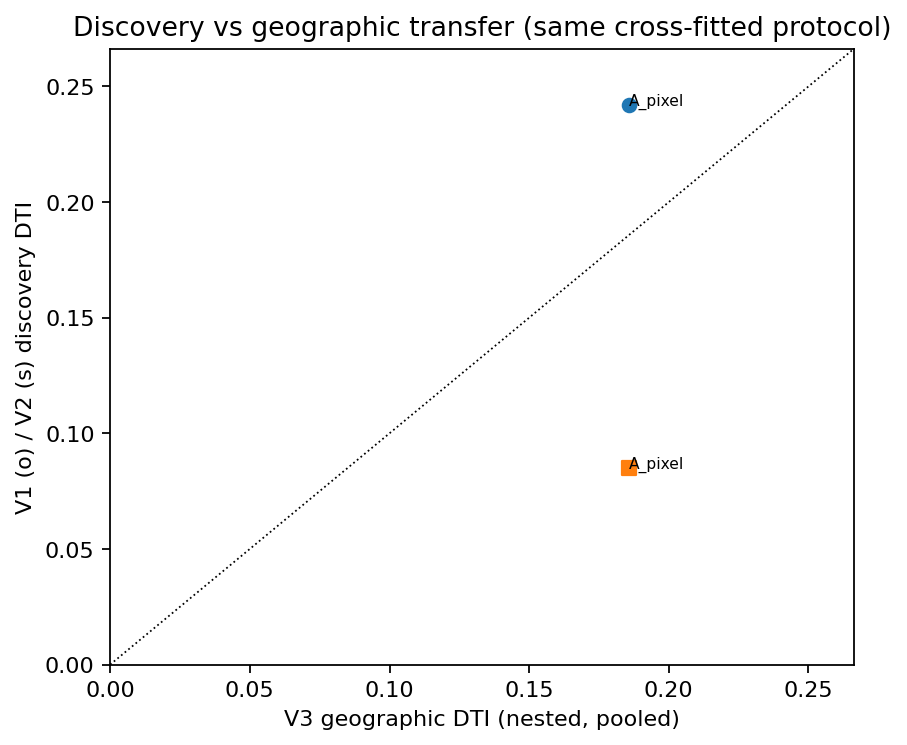

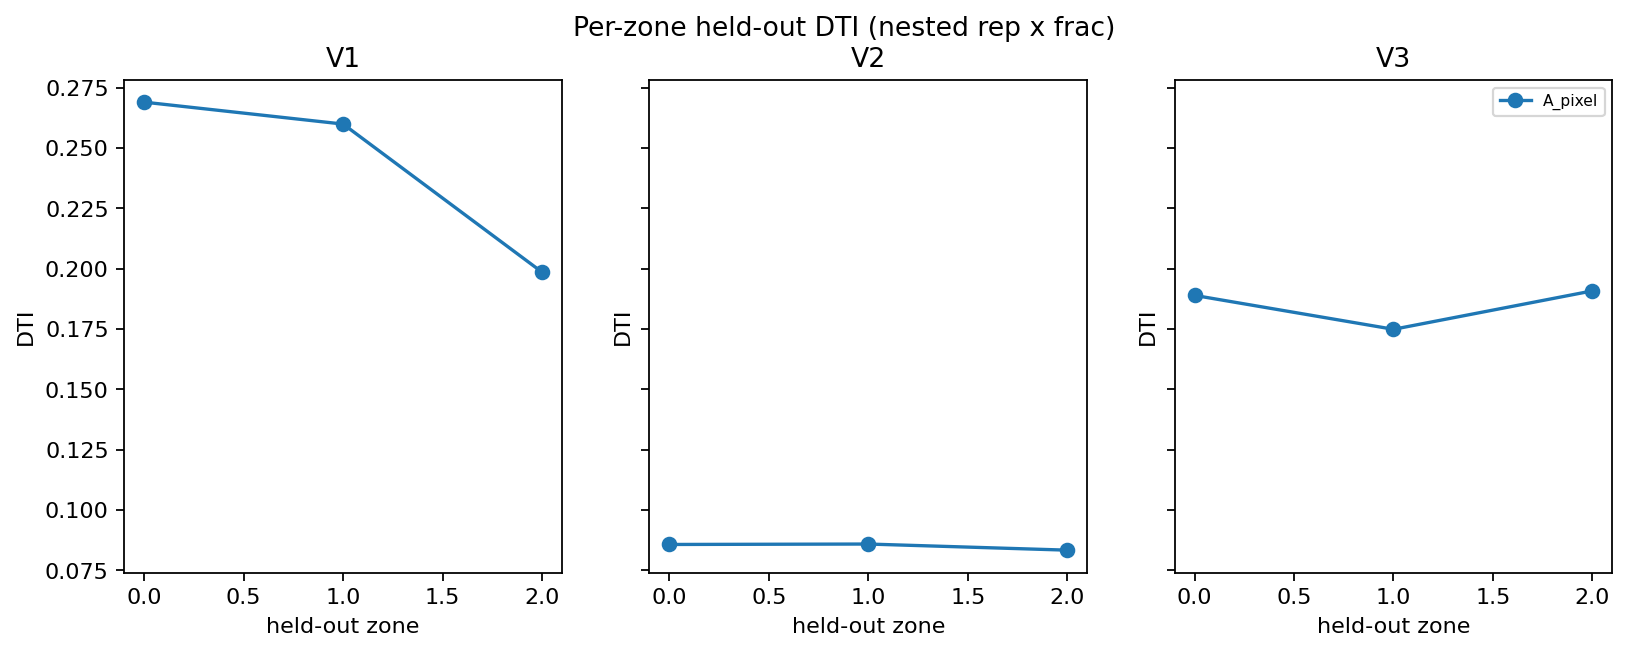

# Scientific decision

Written from persisted tables; numbers are offline cross-fitted estimates, not leaderboard scores.

### 1. Why did W2 fail to generalise?

**Established in this run** (cross-fitted, official scorer):

* W2 pooled DTI: V1 withheld systems 0.2422 (worst zone 0.1986), V2 network completion 0.0851 (worst 0.0834), V3 geographic 0.1856 (worst 0.1749); public leaderboard 0.0942 (external, one file, not tuned on).
* V1 - V3 = +0.0565: the withheld-system estimate overstates geographic transfer (V1 alone is not a reliable predictor of the public score).

**Not established (hypotheses this run cannot decide)**:

* that the public test truth has the V2 composition (corrections / tips / splays) rather than V1's whole systems; V2 is built from real mapped sub-sections, but its class mix is a design choice;
* that the public subset's geology resembles any one geographic fold;
* that the submitted W2 file's area policy (rep from discovery, frac from geography) explains part of the public gap (it was a mixed-policy file, recorded in P6.1).

### 2. Candidate-generation or candidate-ranking bottleneck?

**Verdict: INCONCLUSIVE** (rule: {'GENERATION': 'inventory coverage < 0.6', 'RANKING': 'coverage >= 0.6 and coverage - W2 recovered >= 0.2', 'NEITHER_DOMINANT': 'otherwise', 'geology_unique': '>= 3 systems and >= 5% covered by E2/E3/E4 and by no E1 source, in at least one scenario'}).

_ABSENT_

Same definitions for every pool (units, truth, 300 m, >= 50 % of a system, per-source budget):

_ABSENT_

Reading of the M7 / X2 contradiction: M7's ~12.5 % measured LABEL-FREE crest coverage; X2's 82.9 % 'ranking-limited' share measured missed LENGTH against a pool made of the learned maps at up to 5 % area. The rows `label_free` and `fam:E1_learned` above re-measure both under one definition: when the learned pool covers far more than the label-free one, the contradiction was source coverage plus the definition of 'ranking-limited' (covered by the learned pool at a larger budget), not a disagreement.

### 3. Which new expert provides unique fault recovery?

ABSENT: stage 05 did not complete.

### 4. Does geology-conditioned gating beat static fusion?

ABSENT: no paired comparison against static fusion (stages 09 / 10).

### 5. Does the learned MoE justify its complexity?

ABSENT: selection (stage 10b) did not run.

### 6. Reliability on unseen geography and near-known structures

| scenario | model | dti | worst_zone_dti | worst_zone | fold_std | optimism |
|---|---|---|---|---|---|---|
| V1 | A_pixel | 0.2422 | 0.1986 | 2 | 0.0313 | 0.0000 |
| V2 | A_pixel | 0.0851 | 0.0834 | 2 | 0.0012 | 0.0000 |
| V3 | A_pixel | 0.1856 | 0.1749 | 1 | 0.0071 | 0.0033 |


### 7. Is there a new validated GeoTIFF worth submitting?

* `None` | status **NO_NEW_SUBMISSION** | role none | model RETAIN_W2 | recipe `None` | sha256 `None` | Drive `None`

No new submission: the predeclared selection rule retained W2 (). The reference file stays the submission factory's w2_champion GeoTIFF.

### 8. What should happen next?

**Keep W2 as the reference; test only the representation / area policy of the submission (the pool and the ranking are near their measured ceiling).**

Because: coverage verdict INCONCLUSIVE.


# Next action

Keep W2 as the reference; test only the representation / area policy of the submission (the pool and the ranking are near their measured ceiling).

Evidence: coverage verdict INCONCLUSIVE.

Derived by `gems_bench.geomoe.decide.next_action` (first matching rule of a fixed tree).


stages: {'01_attach': 'COMPLETE', '02_audit': 'COMPLETE', '03_scenarios': 'COMPLETE', '04_candidates': 'FAILED', '05_oracle': 'FAILED', '06_decision': 'COMPLETE', '07_experts': 'FAILED', '08_static': 'FAILED', '09_rules': 'FAILED', '10_learned': 'SKIPPED', '10b_compare': 'FAILED', '11_deployment': 'SKIPPED', '12_export': 'SKIPPED', '13_reports': 'COMPLETE'}


In [16]:
G.s13_reports()
for f in ('candidate_coverage', 'unique_recovery', 'discovery_vs_geography', 'per_zone_dti', 'prediction_case_studies'):
    p = OUT / 'figures' / f'{f}.png'
    if p.exists(): display(Image(str(p)))
display(Markdown((OUT / 'reports/SCIENTIFIC_DECISION.md').read_text()))
display(Markdown((OUT / 'reports/NEXT_ACTION.md').read_text()))
print('stages:', G.status)